# Timing reproducibility of the repeat runs

Parses the logs of the identical repeat runs (`logs/slurm/repeat/repeat_*.out`, produced by `repeat.sbatch`) and summarizes, **for each run**, the step time (median / mean ms per step), the total training time, the final validation bpb, and some extras that help interpret differences (host / GPU, step-time spread, slow steps, warm-up cost, throughput, MFU, peak memory, how far the loss trace deviates from the first run).

- **Total time** = nanochat's own `total time` counter at the last step: pure training step time, excluding the first `WARMUP_STEPS` (10) steps, evals and compile/startup. Median / mean ms per step use the same steps (`dt` of steps after the warm-up), so `mean_ms x steps` is consistent with the total.
- Since all runs share seed, data order and config, **loss and val bpb should be (nearly) identical across runs**; the timing columns show how much wall-clock varies. The `loss_maxdiff_vs_ref` column checks this directly.
- **GPU identity**: runs are identified by the GPU's UUID (`gpu_uuid`, printed at the start of each job log). In the plots, **color = physical GPU** (legend shows a shortened UUID and the host(s) it was seen on), so timing differences can be tied to a specific card.
- Tables (CSV) go to `<repo>/results/tables/`, figures (PNG + PDF) to `<repo>/results/figures/`, all prefixed `timing_repeat_`.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TAG_PREFIX = "repeat"      # run-tag prefix set in repeat.sbatch
WARMUP_STEPS = 10          # nanochat excludes the first 10 steps from its `total time`
SLOW_FACTOR = 1.5          # a step counts as "slow" if dt > SLOW_FACTOR x the run's median dt
ROLL = 25                  # rolling-median window (steps) for the step-time trace plot
OUT_PREFIX = "timing_repeat"

# --- output directories: <repo root>/results/{figures,tables}; the notebook lives in <repo root>/notebooks/
def find_repo_root():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / ".git").exists():
            return p
    return cwd.parent if cwd.name == "notebooks" else cwd

ROOT = find_repo_root()
FIG_DIR, TAB_DIR = ROOT / "results" / "figures", ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
print("repo root:", ROOT)

def savefig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{OUT_PREFIX}_{name}.{ext}", dpi=200, bbox_inches="tight")

def savetable(df, name, index=True):
    df.to_csv(TAB_DIR / f"{OUT_PREFIX}_{name}.csv", index=index)

repo root: /home/simon/work/courses/dsa4k/optimizer-comparison


In [2]:
FILE_RE = re.compile(rf"{re.escape(TAG_PREFIX)}_d(\d+)_(eq_m2|eq|m2|base)_po(on|off)_lr([0-9.eE+-]+?)_rep(\d+)-(\d+)\.out$")
STEP_LINE = re.compile(r"^step (\d+)/(\d+) ", re.M)
F = {  # per-field regexes, applied to each `step ...` line (fields other than step/loss/dt/total time are optional)
    "loss":     re.compile(r"\| loss: ([0-9.]+)"),
    "dt_ms":    re.compile(r"\| dt: ([0-9.]+)ms"),
    "tok_s":    re.compile(r"\| tok/sec: ([\d,]+)"),
    "mfu":      re.compile(r"\| bf16_mfu: ([0-9.]+)"),
    "time_min": re.compile(r"total time: ([0-9.]+)m"),
}
VAL_RE  = re.compile(r"^Step (\d+) \| Validation bpb: ([0-9.]+)", re.M)
HOST_RE = re.compile(r"host=(\S+) gpu=(.+)")
MEM_RE  = re.compile(r"[Pp]eak memory usage:\s*([\d.,]+)\s*MiB")

# Find every logs/slurm/repeat dir at or above the cwd
log_dirs = [p / "logs" / "slurm" / "repeat" for p in [Path.cwd(), *Path.cwd().parents]]
log_dirs = [d for d in log_dirs if d.is_dir()]
print("log dirs:", [str(d) for d in log_dirs])

def parse_log(path):
    text = path.read_text(errors="replace")
    recs = []
    for line in text.splitlines():
        m = STEP_LINE.match(line)
        if not m:
            continue
        rec = {"step": int(m.group(1)), "n_iters": int(m.group(2))}
        for k, rx in F.items():
            mm = rx.search(line)
            rec[k] = float(mm.group(1).replace(",", "")) if mm else np.nan
        recs.append(rec)
    train = pd.DataFrame(recs)
    val = pd.DataFrame(VAL_RE.findall(text), columns=["step", "val_bpb"]).astype(float)
    hm = HOST_RE.search(text)
    host, gpu = (hm.group(1), hm.group(2).strip()) if hm else ("?", "?")
    gpu_name, _, gpu_uuid = gpu.partition(",")      # nvidia-smi prints "name, uuid"
    gpu = (gpu_name.strip(), gpu_uuid.strip())
    mem = MEM_RE.findall(text)
    return train, val, host, gpu, (float(mem[-1].replace(",", "")) if mem else np.nan)

runs = {}   # (config, rep) -> dict; if a rep has several logs keep the one with the most steps
for d in log_dirs:
    for path in d.glob("*.out"):
        m = FILE_RE.search(path.name)
        if not m:
            continue
        train, val, host, gpu, mem = parse_log(path)
        if train.empty:
            continue
        depth, variant, po, lr, rep, job = m.groups()
        config = f"d{depth}_{variant}_po{po}_lr{lr}"
        key = (config, int(rep))
        if key not in runs or len(train) > len(runs[key]["train"]):
            runs[key] = dict(train=train, val=val, host=host, gpu=gpu, peak_mem=mem, job=int(job), path=path,
                             finished=len(train) >= int(train["n_iters"].iloc[0]) and len(val) > 0)

print(f"parsed {len(runs)} runs; configs: {sorted({c for c, _ in runs})}")

log dirs: ['/home/simon/work/courses/dsa4k/optimizer-comparison/logs/slurm/repeat']
parsed 8 runs; configs: ['d8_eq_poon_lr0.025']


In [3]:
# Per-run summary
rows = []
for (config, rep), r in sorted(runs.items()):
    t = r["train"]
    dt = t["dt_ms"].iloc[WARMUP_STEPS:]          # same steps nanochat counts in `total time`
    med = dt.median()
    rows.append(dict(
        config=config, rep=rep, job=r["job"], host=r["host"], gpu_name=r["gpu"][0], gpu_uuid=r["gpu"][1], finished=r["finished"],
        n_steps=len(t),
        total_time_min=t["time_min"].iloc[-1],
        median_ms=med, mean_ms=dt.mean(), std_ms=dt.std(), p95_ms=dt.quantile(0.95), max_ms=dt.max(),
        slow_steps=int((dt > SLOW_FACTOR * med).sum()),
        warmup_s=t["dt_ms"].iloc[:WARMUP_STEPS].sum() / 1000,     # first steps (compile etc.), excluded from the total
        tok_per_s_median=t["tok_s"].median(), mfu_median=t["mfu"].median(), peak_mem_MiB=r["peak_mem"],
        final_val_bpb=r["val"]["val_bpb"].iloc[-1] if len(r["val"]) else np.nan,
        final_train_loss=t["loss"].iloc[-1],
    ))
per_run = pd.DataFrame(rows)
per_run["gpu_id"] = per_run.gpu_uuid.replace("", "unknown")   # physical GPU identity used for coloring / grouping

# How far does each run's loss trace deviate from the reference (first finished) run of its config?
dev = {}
for config, g in per_run[per_run.finished].groupby("config"):
    ref_rep = g.rep.min()
    ref = runs[(config, ref_rep)]["train"].set_index("step")["loss"]
    for rep in g.rep:
        cur = runs[(config, rep)]["train"].set_index("step")["loss"]
        common = ref.index.intersection(cur.index)
        dev[(config, rep)] = (float((ref[common] - cur[common]).abs().max()), ref_rep)
per_run["loss_maxdiff_vs_ref"] = [dev.get((c, r), (np.nan, None))[0] for c, r in zip(per_run.config, per_run.rep)]
per_run["ref_rep"] = [dev.get((c, r), (np.nan, None))[1] for c, r in zip(per_run.config, per_run.rep)]

# Relative to the fastest finished run of the same config
fastest = per_run[per_run.finished].groupby("config").total_time_min.transform("min")
per_run["slower_than_fastest_pct"] = ((per_run.total_time_min / fastest - 1) * 100).where(per_run.finished)

per_run = per_run.round({"total_time_min": 3, "median_ms": 2, "mean_ms": 2, "std_ms": 2, "p95_ms": 2, "max_ms": 1,
                         "warmup_s": 1, "tok_per_s_median": 0, "mfu_median": 2, "peak_mem_MiB": 0,
                         "final_val_bpb": 5, "final_train_loss": 5, "loss_maxdiff_vs_ref": 6, "slower_than_fastest_pct": 2})
savetable(per_run, "per_run", index=False)
per_run.set_index(["config", "rep"])

job    host         gpu_name  \
config             rep                                     
d8_eq_poon_lr0.025 1    1123063  xgpi11  NVIDIA H100 NVL   
                   2    1123064  xgpi11  NVIDIA H100 NVL   
                   3    1123065  xgpi11  NVIDIA H100 NVL   
                   4    1123066  xgpi11  NVIDIA H100 NVL   
                   5    1123067  xgpi11  NVIDIA H100 NVL   
                   6    1123068  xgpi11  NVIDIA H100 NVL   
                   7    1123069  xgpi11  NVIDIA H100 NVL   
                   8    1123070  xgpi11  NVIDIA H100 NVL   

                                                        gpu_uuid  finished  \
config             rep                                                       
d8_eq_poon_lr0.025 1    GPU-59259b36-7656-eb68-ce01-50f68e3c1105      True   
                   2    GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b      True   
                   3    GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b      True   
                   4    GPU-59259b36-7656-eb68-ce01-50f68e3c1105      True   
                   5    GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b      True   
                   6    GPU-59259b36-7656-eb68-ce01-50f68e3c1105      True   
                   7    GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b      True   
                   8    GPU-59259b36-7656-eb68-ce01-50f68e3c1105      True   

                        n_steps  total_time_min  median_ms  mean_ms  std_ms  \
config             rep                                                        
d8_eq_poon_lr0.025 1       1920           16.34     510.38   513.56   23.99   
                   2       1920           15.29     454.70   480.67   37.00   
                   3       1920           14.81     451.88   465.36   30.63   
                   4       1920           16.47     514.17   517.59   29.77   
                   5       1920           14.36     452.00   451.25    3.76   
                   6       1920           15.58     462.36   489.64   39.76   
                   7       1920           14.34     451.47   450.56    4.34   
                   8       1920           16.41     513.95   515.70   23.45   

                        ...  warmup_s  tok_per_s_median  mfu_median  \
config             rep  ...                                           
d8_eq_poon_lr0.025 1    ...      36.8          513746.0       18.20   
                   2    ...      39.1          576370.0       20.41   
                   3    ...      83.7          580120.0       20.54   
                   4    ...      77.1          510100.0       18.06   
                   5    ...      45.9          579964.0       20.54   
                   6    ...      36.3          566841.0       20.07   
                   7    ...      71.3          580660.0       20.56   
                   8    ...      76.8          510108.0       18.06   

                        peak_mem_MiB  final_val_bpb  final_train_loss  \
config             rep                                                  
d8_eq_poon_lr0.025 1         15163.0        0.94319           3.10492   
                   2         15163.0        0.94314           3.10470   
                   3         15163.0        0.94320           3.10495   
                   4         15163.0        0.94299           3.10420   
                   5         15163.0        0.94315           3.10520   
                   6         15163.0        0.94319           3.10479   
                   7         15163.0        0.94319           3.10548   
                   8         15163.0        0.94319           3.10484   

                                                          gpu_id  \
config             rep                                             
d8_eq_poon_lr0.025 1    GPU-59259b36-7656-eb68-ce01-50f68e3c1105   
                   2    GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b   
                   3    GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b   
                   4    GPU-59259b36-7656-eb68-ce01-50f68e3c1105   
     

In [4]:
# Spread across runs, per config (finished runs only): is the wall-clock reproducible?
METRICS = ["total_time_min", "median_ms", "mean_ms", "tok_per_s_median", "final_val_bpb"]
agg_rows = []
for config, g in per_run[per_run.finished].groupby("config"):
    for m in METRICS:
        x = g[m].dropna()
        if x.empty:
            continue
        agg_rows.append(dict(config=config, metric=m, n_runs=len(x), mean=x.mean(), std=x.std(ddof=1) if len(x) > 1 else np.nan,
                             min=x.min(), max=x.max(),
                             range_pct=(x.max() / x.min() - 1) * 100,         # (max - min) / min
                             cv_pct=(x.std(ddof=1) / x.mean() * 100) if len(x) > 1 else np.nan))
spread = pd.DataFrame(agg_rows).round({"mean": 4, "std": 4, "min": 4, "max": 4, "range_pct": 2, "cv_pct": 2})
savetable(spread, "spread", index=False)
display(spread.set_index(["config", "metric"]))

# Grouped by physical GPU (gpu_uuid): are slow runs tied to a particular card?
by_gpu = (per_run[per_run.finished].groupby(["config", "gpu_id"])
          .agg(hosts=("host", lambda s: ", ".join(sorted(set(s)))), reps=("rep", lambda s: ", ".join(map(str, sorted(s)))),
               n_runs=("rep", "size"), total_time_min=("total_time_min", "mean"), median_ms=("median_ms", "mean"),
               mean_ms=("mean_ms", "mean"), slow_steps=("slow_steps", "mean")).round(3))
savetable(by_gpu, "by_gpu")
display(by_gpu)

# Same, grouped by host / GPU model
by_host = (per_run[per_run.finished].groupby(["config", "host", "gpu_name"])
           .agg(n_runs=("rep", "size"), total_time_min=("total_time_min", "mean"), median_ms=("median_ms", "mean"),
                slow_steps=("slow_steps", "mean")).round(3))
savetable(by_host, "by_host")
display(by_host)

n_runs         mean         std  \
config             metric                                              
d8_eq_poon_lr0.025 total_time_min         8      15.4500      0.8965   
                   median_ms              8     476.3638     30.4192   
                   mean_ms                8     485.5412     28.2062   
                   tok_per_s_median       8  552238.6250  34187.9890   
                   final_val_bpb          8       0.9432      0.0001   

                                            min          max  range_pct  \
config             metric                                                 
d8_eq_poon_lr0.025 total_time_min        14.340      16.4700      14.85   
                   median_ms            451.470     514.1700      13.89   
                   mean_ms              450.560     517.5900      14.88   
                   tok_per_s_median  510100.000  580660.0000      13.83   
                   final_val_bpb          0.943       0.9432       0.02   

                                     cv_pct  
config             metric                    
d8_eq_poon_lr0.025 total_time_min      5.80  
                   median_ms           6.39  
                   mean_ms             5.81  
                   tok_per_s_median    6.19  
                   final_val_bpb       0.01

hosts  \
config             gpu_id                                             
d8_eq_poon_lr0.025 GPU-59259b36-7656-eb68-ce01-50f68e3c1105  xgpi11   
                   GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b  xgpi11   

                                                                   reps  \
config             gpu_id                                                 
d8_eq_poon_lr0.025 GPU-59259b36-7656-eb68-ce01-50f68e3c1105  1, 4, 6, 8   
                   GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b  2, 3, 5, 7   

                                                             n_runs  \
config             gpu_id                                             
d8_eq_poon_lr0.025 GPU-59259b36-7656-eb68-ce01-50f68e3c1105       4   
                   GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b       4   

                                                             total_time_min  \
config             gpu_id                                                     
d8_eq_poon_lr0.025 GPU-59259b36-7656-eb68-ce01-50f68e3c1105            16.2   
                   GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b            14.7   

                                                             median_ms  \
config             gpu_id                                                
d8_eq_poon_lr0.025 GPU-59259b36-7656-eb68-ce01-50f68e3c1105    500.215   
                   GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b    452.512   

                                                             mean_ms  \
config             gpu_id                                              
d8_eq_poon_lr0.025 GPU-59259b36-7656-eb68-ce01-50f68e3c1105  509.122   
                   GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b  461.960   

                                                             slow_steps  
config             gpu_id                                                
d8_eq_poon_lr0.025 GPU-59259b36-7656-eb68-ce01-50f68e3c1105        0.25  
                   GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b        0.00

,,,n_runs,total_time_min,median_ms,slow_steps
config,host,gpu_name,,,,
d8_eq_poon_lr0.025,xgpi11,NVIDIA H100 NVL,8,15.45,476.364,0.125


GPUs seen: {'GPU-59259b36-7656-eb68-ce01-50f68e3c1105': 'GPU-59259b36... (xgpi11)', 'GPU-b6bee175-3edc-f36c-1435-01a71f06ab6b': 'GPU-b6bee175... (xgpi11)'}


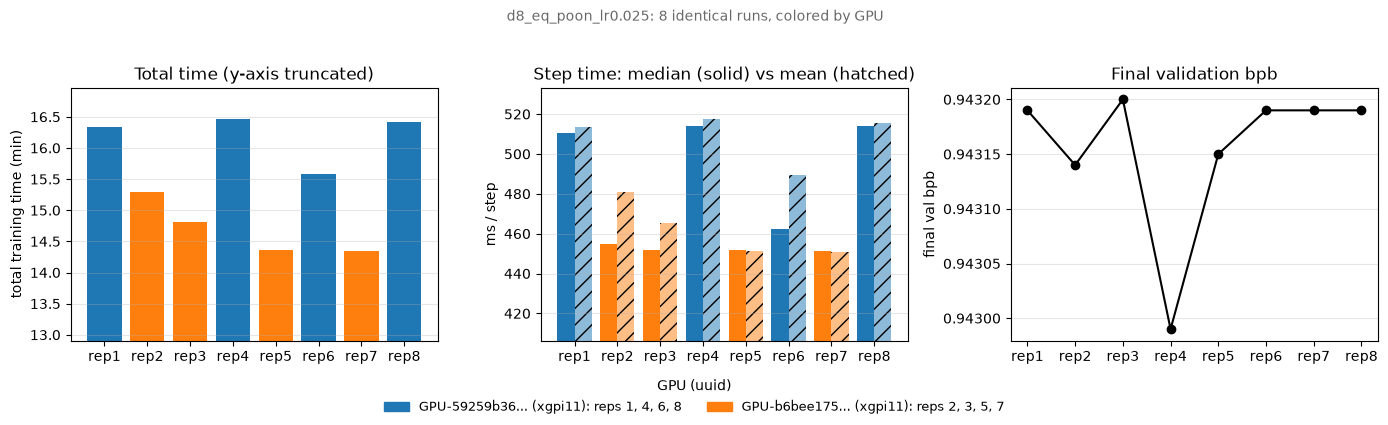

In [5]:
# Per-run comparison: total time, step time and final val bpb (colored by host)
fin = per_run[per_run.finished]
if fin.empty:
    print("no finished runs yet")
else:
    gpus = sorted(fin.gpu_id.unique())
    cmap = {g: plt.get_cmap("tab10")(i % 10) for i, g in enumerate(gpus)}          # color = physical GPU
    gpu_label = {g: f"{g[:12]}... ({', '.join(sorted(set(fin[fin.gpu_id == g].host)))})" for g in gpus}   # short uuid + host(s)
    print("GPUs seen:", gpu_label)
    for config, g in fin.groupby("config"):
        g = g.sort_values("rep")
        x = np.arange(len(g))
        fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
        cols = [cmap[u] for u in g.gpu_id]
        axes[0].bar(x, g.total_time_min, color=cols)
        axes[0].set_ylim(g.total_time_min.min() * 0.9, g.total_time_min.max() * 1.03)
        axes[0].set_ylabel("total training time (min)")
        axes[0].set_title("Total time (y-axis truncated)")
        axes[1].bar(x - 0.2, g.median_ms, width=0.4, color=cols, label="median")
        axes[1].bar(x + 0.2, g.mean_ms, width=0.4, color=cols, alpha=0.5, hatch="//", label="mean")
        axes[1].set_ylim(g.median_ms.min() * 0.9, g.mean_ms.max() * 1.03)
        axes[1].set_ylabel("ms / step")
        axes[1].set_title("Step time: median (solid) vs mean (hatched)")
        axes[2].plot(x, g.final_val_bpb, "o-", color="k")
        axes[2].set_ylabel("final val bpb")
        axes[2].set_title("Final validation bpb")
        for ax in axes:
            ax.set_xticks(x)
            ax.set_xticklabels([f"rep{r}" for r in g.rep])
            ax.grid(alpha=0.3, axis="y")
        used = [u for u in gpus if u in set(g.gpu_id)]
        handles = [plt.Rectangle((0, 0), 1, 1, color=cmap[u]) for u in used]
        fig.legend(handles, [f"{gpu_label[u]}: reps {', '.join(map(str, sorted(g[g.gpu_id == u].rep)))}" for u in used],
                   title="GPU (uuid)", frameon=False, fontsize=9, loc="lower center", ncol=len(used))
        fig.suptitle(f"{config}: {len(g)} identical runs, colored by GPU", fontsize=10, color="dimgray")
        fig.tight_layout(rect=(0, 0.1, 1, 0.95))
        savefig(fig, f"{config}_per_run")
        plt.show()

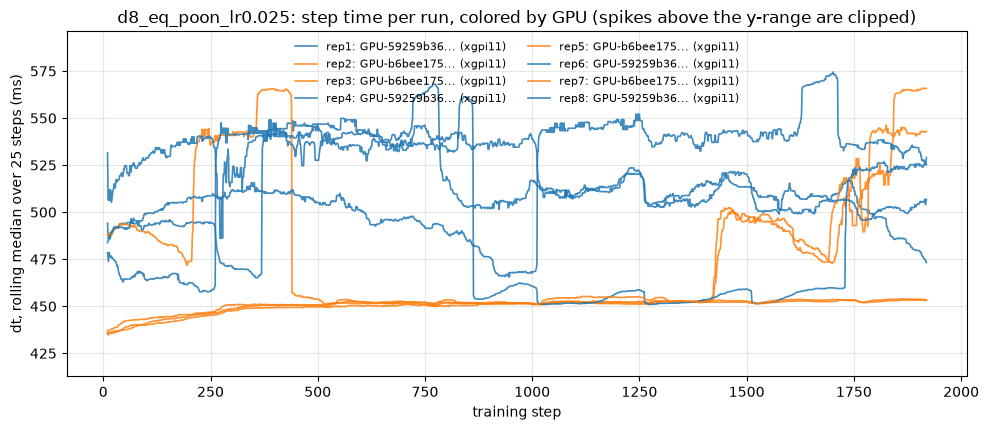

In [6]:
# Step-time traces (rolling median of dt) for every run: where do runs diverge, and are there slow phases / spikes?
if fin.empty:
    print("no finished runs yet")
else:
    for config, g in fin.groupby("config"):
        fig, ax = plt.subplots(figsize=(10, 4.4))
        for rep in sorted(g.rep):
            r = runs[(config, rep)]
            gid = g.loc[g.rep == rep, "gpu_id"].iloc[0]
            dt = r["train"].set_index("step")["dt_ms"].iloc[WARMUP_STEPS:]
            ax.plot(dt.index, dt.rolling(ROLL, min_periods=1).median(), lw=1.2, color=cmap[gid], alpha=0.85, label=f"rep{rep}: {gid[:12]}... ({r['host']})")
        med = g.median_ms.median()
        ax.set_ylim(med * 0.9, med * 1.3)
        ax.set_xlabel("training step")
        ax.set_ylabel(f"dt, rolling median over {ROLL} steps (ms)")
        ax.set_title(f"{config}: step time per run, colored by GPU (spikes above the y-range are clipped)")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=8, ncol=2)
        fig.tight_layout()
        savefig(fig, f"{config}_step_time_traces")
        plt.show()